# 03 · STGCN on METR-LA

Spatio-Temporal Graph Convolutional Network (Yu, Yin & Zhu, IJCAI 2018), implemented in `src/models/stgcn/`.

Runs on **Google Colab** (use a GPU runtime) or **locally** (CUDA, Apple MPS or CPU).
Requires the processed files from `01_data_preprocess.ipynb`.

The notebook builds the graph and model, then trains with validation-based early stopping
(or reuses a finished run in `results/`), and evaluates on the held-out test period with
MAE, RMSE and MAPE at 15, 30 and 60 minutes. The same training code runs from the command line:
`python -m src.models.stgcn.train --adjacency distance`.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/mansiguptacs/CMPE_258_TrafficForecastingUsing_GraphNN.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    repo = Path("/content/CMPE_258_TrafficForecastingUsing_GraphNN")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(repo)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tables", "pyyaml"], check=True)
else:
    repo = Path.cwd()
    while not (repo / "configs" / "metr_la.yaml").exists():
        if repo.parent == repo:
            raise RuntimeError("Start this notebook from inside the project repository")
        repo = repo.parent

os.chdir(repo)
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
print("Colab" if IN_COLAB else "Local", "| repo:", repo)

Local | repo: /Users/mansigupta/IdeasProject/DL/CMPE_258_TrafficForecastingUsing_GraphNN


In [2]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from src.config import load_config, processed_dir
from src.data.pipeline import load_processed, make_datasets, PROCESSED_FILE
from src.eval.metrics import horizon_metrics
from src.models.stgcn.graph import get_adjacency, scaled_laplacian
from src.models.stgcn.train import build_model, train, run_dir, pick_device

cfg = load_config()
if not (processed_dir(cfg) / PROCESSED_FILE).exists():
    raise FileNotFoundError("Processed data not found. Run 01_data_preprocess.ipynb first.")

device = pick_device()
data = load_processed(cfg)
datasets = make_datasets(cfg, data)
interval = cfg["dataset"]["interval_minutes"]
print("device:", device)
print({split: len(ds) for split, ds in datasets.items()}, "windows")

device: mps
{'train': 23967, 'val': 3404, 'test': 6832} windows


## 1. Graph

Chebyshev graph convolution needs the scaled Laplacian
$\tilde L = 2L/\lambda_{max} - I$, with $L = I - D^{-1/2} W D^{-1/2}$.
The adjacency is chosen by `graph.adjacency` in the config (`distance` or `correlation`).
The road adjacency is directed, so it is symmetrized for STGCN.

adjacency: distance, 1313 undirected edges
neighbours per sensor: mean 12.7, min 0, max 25
scaled Laplacian eigenvalues in [-1.00, 1.00]


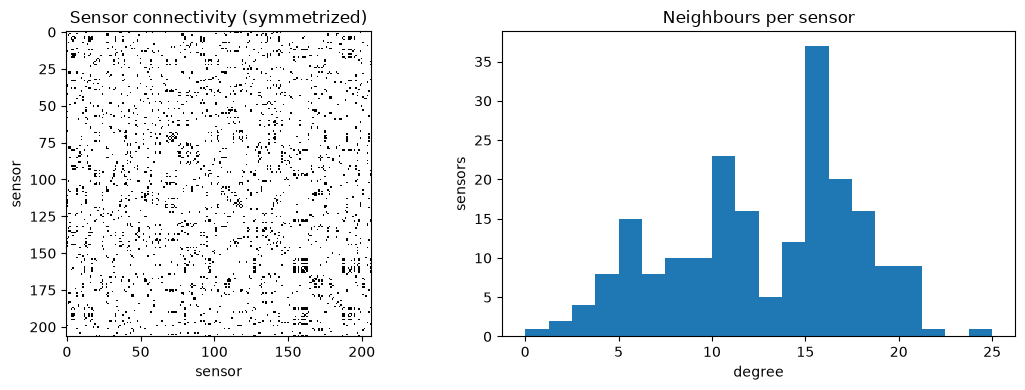

In [3]:
adj = get_adjacency(cfg, data)
lap = scaled_laplacian(adj)
eig = np.linalg.eigvalsh(lap)

sym = np.maximum(adj, adj.T)
np.fill_diagonal(sym, 0)
degree = (sym > 0).sum(axis=1)
print(f"adjacency: {cfg['graph']['adjacency']}, {int((sym > 0).sum() // 2)} undirected edges")
print(f"neighbours per sensor: mean {degree.mean():.1f}, min {degree.min()}, max {degree.max()}")
print(f"scaled Laplacian eigenvalues in [{eig.min():.2f}, {eig.max():.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(sym > 0, cmap="Greys", interpolation="nearest")
axes[0].set(title="Sensor connectivity (symmetrized)", xlabel="sensor", ylabel="sensor")
axes[1].hist(degree, bins=20)
axes[1].set(title="Neighbours per sensor", xlabel="degree", ylabel="sensors")
plt.tight_layout(); plt.show()

## 2. Model

Two ST-Conv blocks, each: gated temporal conv → Chebyshev graph conv → gated temporal conv → layer norm.
With 12 input steps and temporal kernel 3, the blocks shrink time from 12 to 4; the output layer
collapses the remaining 4 steps and predicts all 12 future steps at once.

In [4]:
model = build_model(cfg, data, device)
print(model)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

x, y, y_mask = next(iter(DataLoader(datasets["train"], batch_size=64)))
with torch.no_grad():
    out = model(x.to(device))
print("input :", tuple(x.shape), "[batch, time, sensors, features]")
print("output:", tuple(out.shape), "[batch, future steps, sensors]")

STGCN(
  (blocks): ModuleList(
    (0): STConvBlock(
      (temporal1): TemporalGLU(
        (conv): Conv2d(1, 64, kernel_size=(3, 1), stride=(1, 1))
        (align): Conv2d(1, 32, kernel_size=(1, 1), stride=(1, 1))
      )
      (spatial): ChebGraphConv(
        (theta): Conv2d(96, 32, kernel_size=(1, 1), stride=(1, 1))
      )
      (temporal2): TemporalGLU(
        (conv): Conv2d(32, 128, kernel_size=(3, 1), stride=(1, 1))
        (align): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1))
      )
      (norm): LayerNorm((207, 64), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.3, inplace=False)
    )
    (1): STConvBlock(
      (temporal1): TemporalGLU(
        (conv): Conv2d(64, 64, kernel_size=(3, 1), stride=(1, 1))
        (align): Conv2d(64, 32, kernel_size=(1, 1), stride=(1, 1))
      )
      (spatial): ChebGraphConv(
        (theta): Conv2d(96, 32, kernel_size=(1, 1), stride=(1, 1))
      )
      (temporal2): TemporalGLU(
        (conv): Conv2d(32,

input : (64, 12, 207, 1) [batch, time, sensors, features]
output: (64, 12, 207) [batch, future steps, sensors]


## 3. Training

Loss is masked MAE in mph, so missing targets do not count. Adam with the learning rate halved
when validation error stalls, early stopping on validation MAE, best checkpoint kept.
If a finished run exists for this graph it is reused; delete `results/stgcn_<graph>/` to retrain
(about 40 s per epoch on Apple MPS).

38 epochs, best epoch 30, 36.7 min on mps


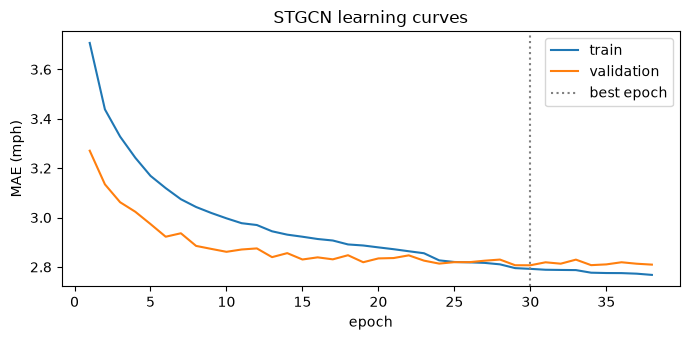

In [5]:
tag = f"stgcn_{cfg['graph']['adjacency']}"
out_dir = run_dir(cfg, tag)
if not (out_dir / "test_predictions.npz").exists():
    train(cfg, tag=tag)

history = pd.DataFrame(json.load(open(out_dir / "history.json")))
results = json.load(open(out_dir / "metrics.json"))
print(f"{results['epochs_run']} epochs, best epoch {results['best_epoch']}, {results['train_minutes']:.1f} min on {results['device']}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history["epoch"], history["train_mae"], label="train")
ax.plot(history["epoch"], history["val_mae"], label="validation")
ax.axvline(results["best_epoch"], color="gray", ls=":", label="best epoch")
ax.set(title="STGCN learning curves", xlabel="epoch", ylabel="MAE (mph)")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Test results

Scored on the test period (4 June to 27 June 2012) only, on observed readings only.

In [6]:
rows = {name: {"MAE (mph)": m["mae"], "RMSE (mph)": m["rmse"], "MAPE (%)": m["mape"]}
        for name, m in results["test"].items()}
table = pd.DataFrame(rows).T.round(3)
display(table)

val_rows = {name: {"MAE (mph)": m["mae"], "RMSE (mph)": m["rmse"], "MAPE (%)": m["mape"]}
            for name, m in results["val"].items()}
print("validation split, for reference:")
display(pd.DataFrame(val_rows).T.round(3))

,MAE (mph),RMSE (mph),MAPE (%)
15min,2.797,5.334,7.399
30min,3.224,6.475,9.094
60min,3.753,7.696,11.215
average,3.197,6.445,9.022


validation split, for reference:


,MAE (mph),RMSE (mph),MAPE (%)
15min,2.491,4.876,6.485
30min,2.832,5.883,7.910
60min,3.250,6.970,9.624
average,2.807,5.852,7.825


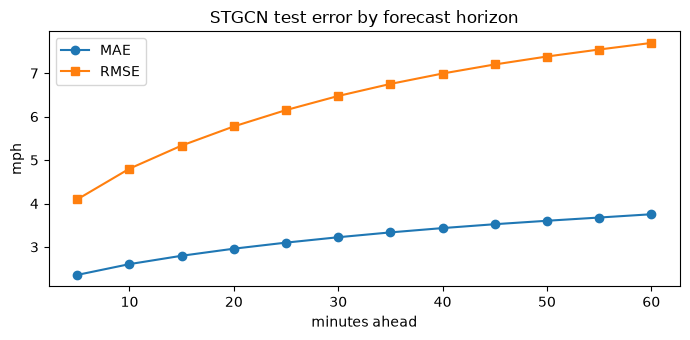

In [7]:
pred = np.load(out_dir / "test_predictions.npz")["pred"]
t0, t1 = data["meta"]["split_index"]["test"]
w = cfg["windows"]
n_win = pred.shape[0]
target = np.stack([data["speeds"][t0 + i + w["input_len"]: t0 + i + w["input_len"] + w["output_len"]]
                   for i in range(n_win)])
mask = np.stack([data["observed"][t0 + i + w["input_len"]: t0 + i + w["input_len"] + w["output_len"]]
                 for i in range(n_win)])

# error as the forecast reaches further ahead
steps = np.arange(1, w["output_len"] + 1)
mae_by_step = [horizon_metrics(pred, target, mask, horizons=(s,))[f"{s * interval}min"]["mae"] for s in steps]
rmse_by_step = [horizon_metrics(pred, target, mask, horizons=(s,))[f"{s * interval}min"]["rmse"] for s in steps]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(steps * interval, mae_by_step, marker="o", label="MAE")
ax.plot(steps * interval, rmse_by_step, marker="s", label="RMSE")
ax.set(title="STGCN test error by forecast horizon", xlabel="minutes ahead", ylabel="mph")
ax.legend(); plt.tight_layout(); plt.show()

## 5. Predicted vs actual speeds

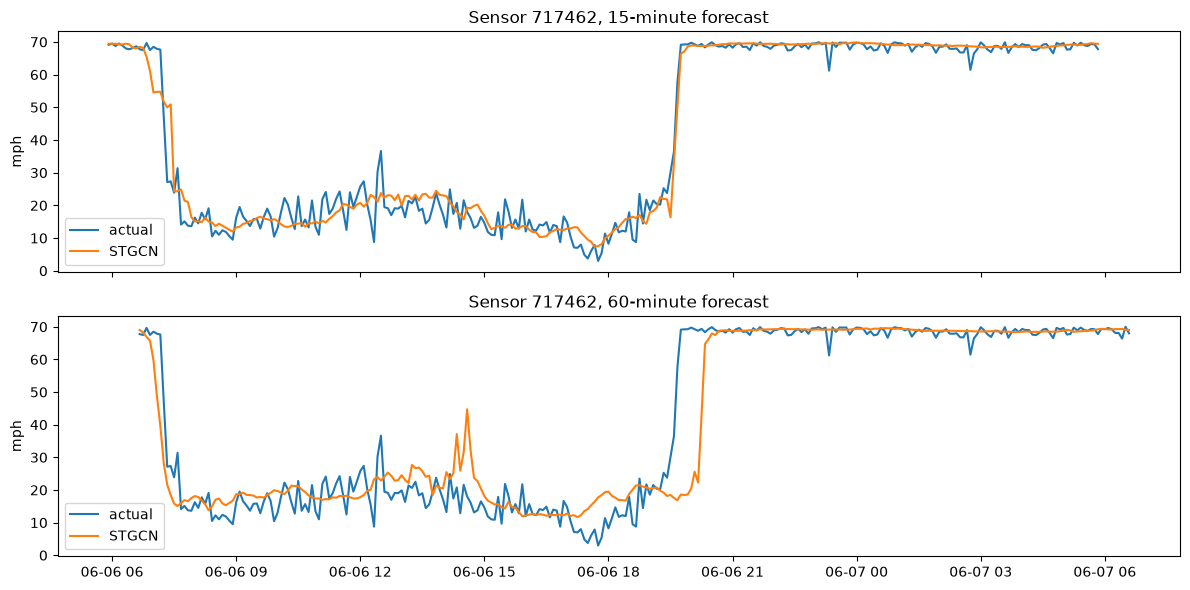

In [8]:
# pick the sensor with the most variable speed on a fully observed test weekday
per_day = 24 * 60 // interval
day_start = 2 * per_day          # third day of the test period (windows are indexed by forecast origin)
day = slice(day_start, day_start + per_day)
obs_share = mask[day, 0].mean(axis=0)
spread = np.where(obs_share > 0.99, target[day, 0].std(axis=0), -1)
sensor = int(np.argmax(spread))

clock = pd.to_datetime(data["timestamps"][t0 + w["input_len"]:][:n_win])
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, h in zip(axes, (3, 12)):
    actual = np.where(mask[day, h - 1, sensor], target[day, h - 1, sensor], np.nan)
    when = clock[day] + pd.Timedelta(minutes=(h - 1) * interval)
    ax.plot(when, actual, label="actual", lw=1.5)
    ax.plot(when, pred[day, h - 1, sensor], label="STGCN", lw=1.5)
    ax.set(title=f"Sensor {data['sensor_ids'][sensor]}, {h * interval}-minute forecast", ylabel="mph")
    ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

## 6. Where does the model do worse?

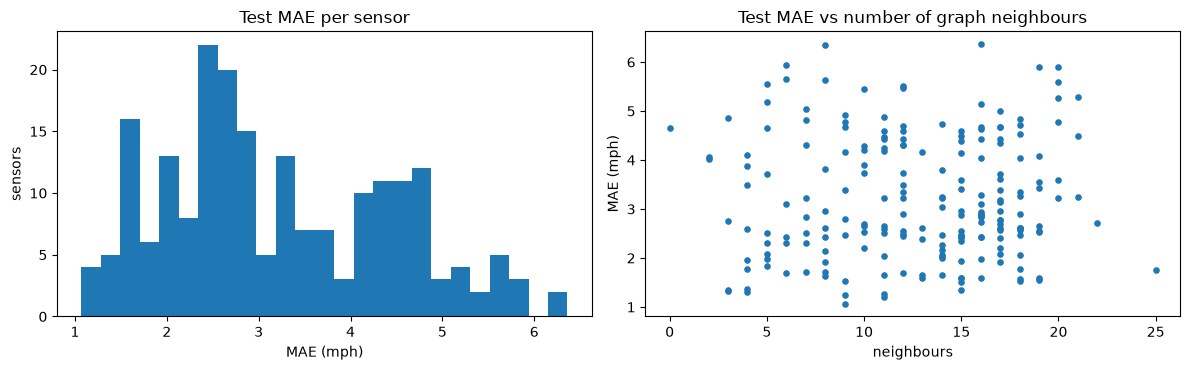

sensor MAE: median 2.89, worst 6.36 mph
correlation between neighbours and MAE: 0.03
worst sensors: [('718045', 6.36, 16), ('716960', 6.35, 8), ('773939', 5.93, 6), ('717466', 5.9, 19), ('717462', 5.9, 20)] (id, MAE, neighbours)


In [9]:
# per-sensor MAE (all forecast steps) against the number of neighbours in the graph
err = np.abs(pred - target) * mask
sensor_mae = err.sum(axis=(0, 1)) / np.maximum(mask.sum(axis=(0, 1)), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(sensor_mae, bins=25)
axes[0].set(title="Test MAE per sensor", xlabel="MAE (mph)", ylabel="sensors")
axes[1].scatter(degree, sensor_mae, s=14)
axes[1].set(title="Test MAE vs number of graph neighbours", xlabel="neighbours", ylabel="MAE (mph)")
plt.tight_layout(); plt.show()

print(f"sensor MAE: median {np.median(sensor_mae):.2f}, worst {sensor_mae.max():.2f} mph")
print(f"correlation between neighbours and MAE: {np.corrcoef(degree, sensor_mae)[0, 1]:.2f}")
worst = np.argsort(sensor_mae)[::-1][:5]
print("worst sensors:", [(data['sensor_ids'][i], round(float(sensor_mae[i]), 2), int(degree[i])) for i in worst],
      "(id, MAE, neighbours)")

## 7. Does the graph help? Ablation without edges

The same STGCN is trained with an empty graph (`adjacency: identity`). Every layer, parameter count and
training setting is identical; the only change is that sensors can no longer see their neighbours.
The comparison is on the same test windows. This section compares single runs (seed 42);
section 8 repeats the comparison over three seeds.

In [10]:
no_graph_dir = run_dir(cfg, "stgcn_no_graph_s42")
if not (no_graph_dir / "test_predictions.npz").exists():
    raise FileNotFoundError("Run: python -m src.models.stgcn.experiments run")
res_ng = json.load(open(no_graph_dir / "metrics.json"))
pred_ng = np.load(no_graph_dir / "test_predictions.npz")["pred"]

names = ["15min", "30min", "60min", "average"]
cmp = pd.DataFrame({
    ("MAE (mph)", "graph"): [results["test"][k]["mae"] for k in names],
    ("MAE (mph)", "no graph"): [res_ng["test"][k]["mae"] for k in names],
    ("RMSE (mph)", "graph"): [results["test"][k]["rmse"] for k in names],
    ("RMSE (mph)", "no graph"): [res_ng["test"][k]["rmse"] for k in names],
    ("MAPE (%)", "graph"): [results["test"][k]["mape"] for k in names],
    ("MAPE (%)", "no graph"): [res_ng["test"][k]["mape"] for k in names],
}, index=names).round(3)
display(cmp)
print(f"epochs run: graph {results['epochs_run']} (best {results['best_epoch']}), "
      f"no graph {res_ng['epochs_run']} (best {res_ng['best_epoch']})")

MAE (mph)          RMSE (mph)          MAPE (%)         
            graph no graph      graph no graph    graph no graph
15min       2.797    3.011      5.334    5.926    7.399    8.169
30min       3.224    3.563      6.475    7.323    9.094   10.475
60min       3.753    4.131      7.696    8.553   11.215   12.836
average     3.197    3.493      6.445    7.197    9.022   10.209

epochs run: graph 38 (best 30), no graph 64 (best 56)


,horizon,traffic,share of readings,MAE graph,MAE no graph,graph improves by
0,15 min,congested (<40 mph),12.4%,6.85,8.08,15.3%
1,15 min,free flow,87.6%,2.23,2.30,3.0%
2,30 min,congested (<40 mph),12.4%,8.85,11.21,21.1%
3,30 min,free flow,87.6%,2.43,2.48,2.2%
4,60 min,congested (<40 mph),12.4%,11.38,14.18,19.8%
5,60 min,free flow,87.6%,2.68,2.71,1.4%


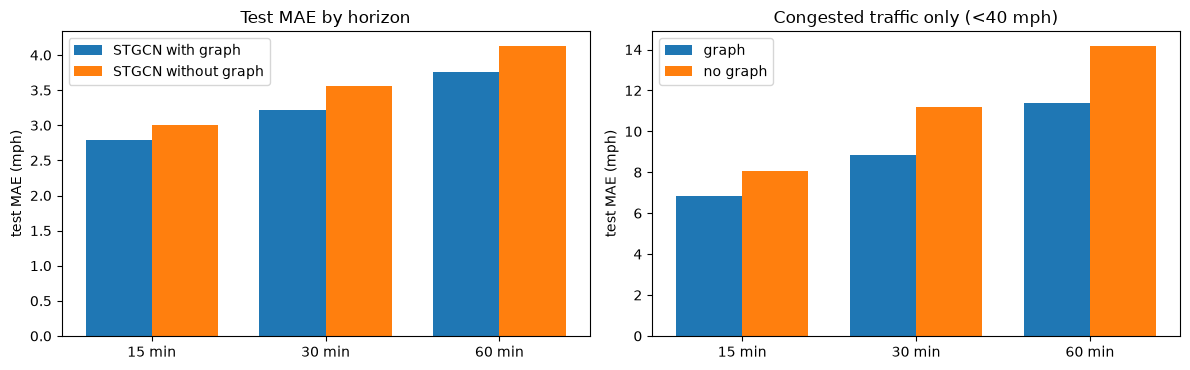

In [11]:
# error split by traffic state: congested = realised speed below 40 mph
def state_mae(p, h, congested):
    t, m = target[:, h - 1], mask[:, h - 1]
    sel = m & ((t < 40) if congested else (t >= 40))
    return np.abs(p[:, h - 1][sel] - t[sel]).mean(), sel.sum() / m.sum()

rows = []
for h in (3, 6, 12):
    for congested in (True, False):
        g, share = state_mae(pred, h, congested)
        n, _ = state_mae(pred_ng, h, congested)
        rows.append({"horizon": f"{h * interval} min", "traffic": "congested (<40 mph)" if congested else "free flow",
                     "share of readings": f"{share:.1%}", "MAE graph": round(g, 2), "MAE no graph": round(n, 2),
                     "graph improves by": f"{(n - g) / n:.1%}"})
state = pd.DataFrame(rows)
display(state)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x_pos = np.arange(3); wd = 0.38
axes[0].bar(x_pos - wd / 2, [results["test"][k]["mae"] for k in names[:3]], wd, label="STGCN with graph")
axes[0].bar(x_pos + wd / 2, [res_ng["test"][k]["mae"] for k in names[:3]], wd, label="STGCN without graph")
axes[0].set(xticks=x_pos, xticklabels=["15 min", "30 min", "60 min"], ylabel="test MAE (mph)", title="Test MAE by horizon")
axes[0].legend()
cong = state[state["traffic"].str.startswith("congested")]
free = state[state["traffic"] == "free flow"]
axes[1].bar(x_pos - wd / 2, cong["MAE graph"], wd, label="graph")
axes[1].bar(x_pos + wd / 2, cong["MAE no graph"], wd, label="no graph")
axes[1].set(xticks=x_pos, xticklabels=["15 min", "30 min", "60 min"], ylabel="test MAE (mph)", title="Congested traffic only (<40 mph)")
axes[1].legend()
plt.tight_layout(); plt.show()

In [12]:
# per-sensor gain from the graph, against how many neighbours the sensor has
mae_ng = (np.abs(pred_ng - target) * mask).sum(axis=(0, 1)) / np.maximum(mask.sum(axis=(0, 1)), 1)
gain = mae_ng - sensor_mae
print(f"graph model is better on {(gain > 0).sum()} of {len(gain)} sensors; mean gain {gain.mean():.2f} mph, median {np.median(gain):.2f}")
print(f"correlation between gain and number of neighbours: {np.corrcoef(degree, gain)[0, 1]:.2f}")

graph model is better on 186 of 207 sensors; mean gain 0.30 mph, median 0.21
correlation between gain and number of neighbours: 0.27


## 8. Graph variants over three seeds

A single run can be lucky, so each variant is trained with seeds 42, 43 and 44
(`python -m src.models.stgcn.experiments run`, early stopping with an 80-epoch cap):

- **distance**: road-distance graph from the DCRNN authors (`adj_mx.pkl`)
- **correlation**: top-10 most correlated sensors, built from the training period only
- **no graph**: no edges

Numbers are mean ± standard deviation over the three seeds.

,15min MAE,30min MAE,60min MAE,average MAE,15min RMSE,30min RMSE,60min RMSE,average RMSE
distance graph,2.799 ± 0.035,3.223 ± 0.039,3.737 ± 0.053,3.191 ± 0.041,5.336 ± 0.051,6.490 ± 0.071,7.714 ± 0.091,6.454 ± 0.069
correlation graph,2.808 ± 0.044,3.220 ± 0.053,3.738 ± 0.049,3.194 ± 0.046,5.392 ± 0.129,6.498 ± 0.148,7.719 ± 0.121,6.470 ± 0.124
no graph,2.948 ± 0.070,3.450 ± 0.123,3.998 ± 0.142,3.393 ± 0.109,5.807 ± 0.140,7.086 ± 0.267,8.300 ± 0.278,6.987 ± 0.235


distance graph     best epochs per seed: [30, 43, 29]
correlation graph  best epochs per seed: [19, 27, 22]
no graph           best epochs per seed: [56, 29, 46]


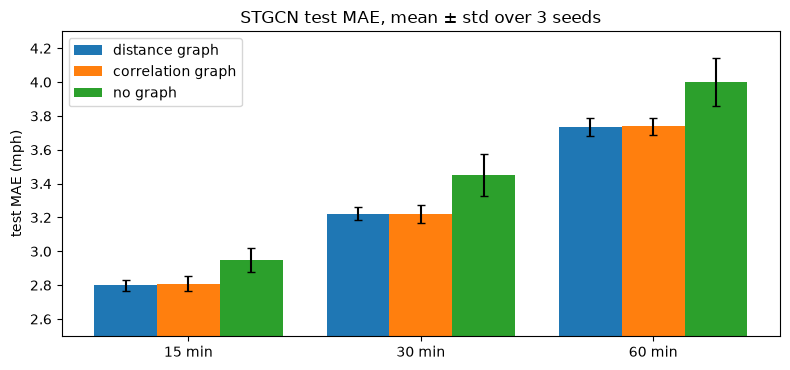

In [13]:
summary = json.load(open("results/stgcn_summary.json"))
graph_variants = {"distance": "distance graph", "correlation": "correlation graph", "no_graph": "no graph"}

rows = {}
for v, label in graph_variants.items():
    s = summary[v]["test"]
    rows[label] = {f"{h} {k.upper()}": f"{s[h][k]['mean']:.3f} ± {s[h][k]['std']:.3f}"
                   for k in ("mae", "rmse") for h in ("15min", "30min", "60min", "average")}
display(pd.DataFrame(rows).T)
for v, label in graph_variants.items():
    print(f"{label:18s} best epochs per seed: {summary[v]['best_epochs']}")

fig, ax = plt.subplots(figsize=(8, 3.8))
hs = ["15min", "30min", "60min"]
x_pos = np.arange(len(hs)); wd = 0.27
for j, (v, label) in enumerate(graph_variants.items()):
    s = summary[v]["test"]
    ax.bar(x_pos + (j - 1) * wd, [s[h]["mae"]["mean"] for h in hs], wd,
           yerr=[s[h]["mae"]["std"] for h in hs], capsize=3, label=label)
ax.set(xticks=x_pos, xticklabels=["15 min", "30 min", "60 min"], ylabel="test MAE (mph)",
       title="STGCN test MAE, mean ± std over 3 seeds", ylim=(2.5, 4.3))
ax.legend(); plt.tight_layout(); plt.show()

## 9. Robustness to missing inputs

Real sensors fail, so we hide extra test inputs and score the trained models again (`python -m src.eval.missing_eval`).
Only the inputs are hidden; targets stay the original real readings, so every setting is scored on the same values.
Hidden inputs are re-filled the same way the model was trained (forward-fill by default).

- **random readings**: each test reading is hidden independently with the given probability
- **sensor outage**: a share of sensors is hidden for the whole test period; we report the error on those dead sensors

Each point averages 3 trained seeds × 3 random masks (rate 0: 3 seeds).

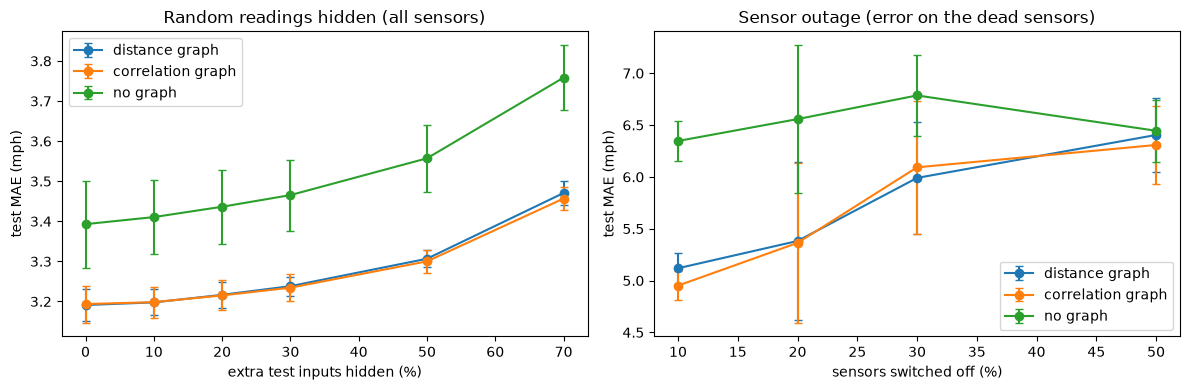

random readings hidden: test MAE (mph) on all sensors


variant,correlation graph,distance graph,no graph
rate,,,
0.0,3.194,3.191,3.393
0.1,3.198,3.198,3.410
0.2,3.215,3.217,3.436
0.3,3.234,3.238,3.465
0.5,3.300,3.307,3.557
0.7,3.457,3.471,3.758


sensor outage: test MAE (mph) on the dead sensors


variant,correlation graph,distance graph,no graph
rate,,,
0.1,4.951,5.119,6.346
0.2,5.363,5.382,6.557
0.3,6.092,5.990,6.786
0.5,6.308,6.404,6.445


In [14]:
miss = pd.DataFrame([
    {"variant": r["variant"], "seed": r["seed"], "mode": r["mode"], "rate": r["rate"], "mask_seed": r["mask_seed"],
     "mae_all": r["all"]["average"]["mae"],
     "mae_hidden": r["hidden_sensors"]["average"]["mae"] if "hidden_sensors" in r else np.nan}
    for r in json.load(open("results/missing_eval.json"))
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for v, label in graph_variants.items():
    pt = miss[(miss.variant == v) & (miss["mode"] == "point")].groupby("rate")["mae_all"].agg(["mean", "std"])
    axes[0].errorbar(pt.index * 100, pt["mean"], yerr=pt["std"], marker="o", capsize=3, label=label)
    se = miss[(miss.variant == v) & (miss["mode"] == "sensor")].groupby("rate")["mae_hidden"].agg(["mean", "std"])
    axes[1].errorbar(se.index * 100, se["mean"], yerr=se["std"], marker="o", capsize=3, label=label)
axes[0].set(title="Random readings hidden (all sensors)", xlabel="extra test inputs hidden (%)", ylabel="test MAE (mph)")
axes[1].set(title="Sensor outage (error on the dead sensors)", xlabel="sensors switched off (%)", ylabel="test MAE (mph)")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

labelled = miss[miss.variant.isin(graph_variants)].assign(variant=lambda d: d.variant.map(graph_variants))
print("random readings hidden: test MAE (mph) on all sensors")
display(labelled[labelled["mode"] == "point"].pivot_table(index="rate", columns="variant", values="mae_all").round(3))
print("sensor outage: test MAE (mph) on the dead sensors")
display(labelled[labelled["mode"] == "sensor"].pivot_table(index="rate", columns="variant", values="mae_hidden").round(3))

## 10. How missing inputs are filled

Section 9 suggests that forward-fill hurts during long outages: a dead sensor keeps repeating its last reading
for days, and the graph passes that stale value to its neighbours. So we train the distance-graph STGCN
(seed 42) with other input choices, set by `missing.input_imputation` and `missing.mask_channel` in the config:

- **ffill**: carry the last real reading forward (default)
- **ffill + mask**: as above, plus a second input channel that is 1 for real readings and 0 for filled ones
- **mean**: fill with the sensor's training mean
- **mean + mask**: mean fill plus the indicator channel

These are single runs, so differences under about 0.05 mph are within seed noise (see section 8).

test MAE (mph) on the normal test set, seed 42:


,15min,30min,60min,average
ffill,2.797,3.224,3.753,3.197
ffill + mask,2.792,3.212,3.715,3.177
mean,2.739,3.142,3.619,3.106
mean + mask,2.782,3.195,3.647,3.148


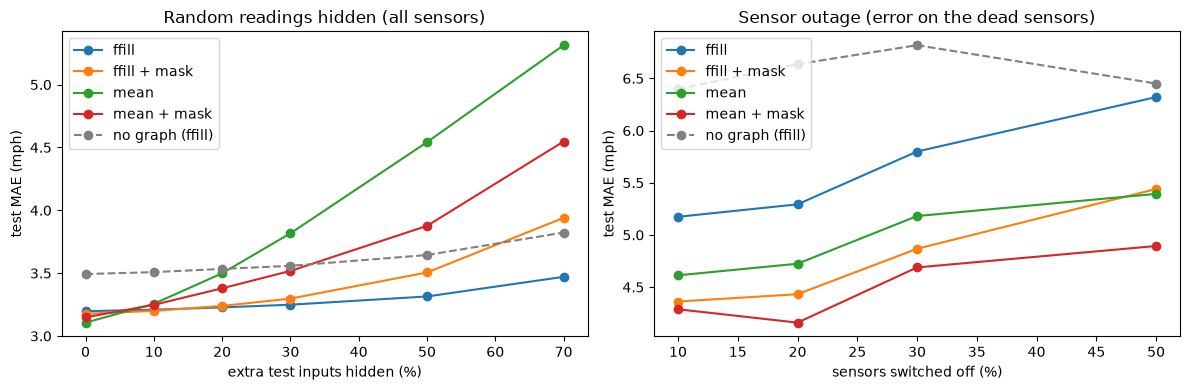

In [15]:
imputation_variants = {"distance": "ffill", "distance_ffill_mask": "ffill + mask",
                       "distance_mean": "mean", "distance_mean_mask": "mean + mask"}
from src.models.stgcn.experiments import tag_for
seed42_metrics = {label: json.load(open(run_dir(cfg, tag_for(v, 42)) / "metrics.json"))["test"]
                  for v, label in imputation_variants.items()}
clean = pd.DataFrame({label: {h: m[h]["mae"] for h in ("15min", "30min", "60min", "average")}
                      for label, m in seed42_metrics.items()}).T.round(3)
print("test MAE (mph) on the normal test set, seed 42:")
display(clean)

seed42 = miss[miss.seed == 42]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for v, label in {**imputation_variants, "no_graph": "no graph (ffill)"}.items():
    style = dict(ls="--", color="gray") if v == "no_graph" else {}
    pt = seed42[(seed42.variant == v) & (seed42["mode"] == "point")].groupby("rate")["mae_all"].mean()
    axes[0].plot(pt.index * 100, pt.values, marker="o", label=label, **style)
    se = seed42[(seed42.variant == v) & (seed42["mode"] == "sensor")].groupby("rate")["mae_hidden"].mean()
    axes[1].plot(se.index * 100, se.values, marker="o", label=label, **style)
axes[0].set(title="Random readings hidden (all sensors)", xlabel="extra test inputs hidden (%)", ylabel="test MAE (mph)")
axes[1].set(title="Sensor outage (error on the dead sensors)", xlabel="sensors switched off (%)", ylabel="test MAE (mph)")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

## Findings so far

1. **The graph helps, and the gain is not seed noise.** Over three seeds, STGCN with a graph has an average test MAE
   of about 3.19 mph against 3.39 without one. The gap grows with the horizon, and the no-graph model is also less
   stable across seeds.
2. **Distance and correlation graphs are equally good.** They share only 28% of their edges but give the same error;
   the correlation graph reaches its best epoch sooner.
3. **Scattered gaps are handled well.** With 70% of test inputs hidden at random, MAE rises by only about 0.3 mph,
   and the graph keeps its lead.
4. **Outages are where the graph matters most, and where the filling method matters most.** With 10–30% of sensors
   switched off, the graph lowers the error on dead sensors by roughly 10–20%. With forward-fill, large outages
   cancel the benefit, because the frozen values spread to neighbours. A missing-indicator channel with mean fill
   fixes this (about 15–25% lower error on dead sensors than forward-fill), but it is clearly worse when many
   scattered readings are missing.
5. **No single filling method wins everywhere.** Forward-fill is best for short gaps, mean fill plus the indicator
   for long outages.

## Next

- Train with extra random input masking (augmentation), so one model handles both kinds of gaps.
- Repeat the imputation variants over three seeds.
- Small hyperparameter search, then the final STGCN configuration.
- Compare against the historical-average, LSTM and DCRNN results under the same split and metrics.